In [1]:
# Import essential libraries for data analysis

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Set visualization style
sns.set_style("whitegrid")

In [2]:
# Load IBM Telco Customer Churn dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Display first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Check number of rows and columns

print("Dataset Shape:", df.shape)

# Check total records
print("Total Customers:", df.shape[0])

# Check total features
print("Total Columns:", df.shape[1])

Dataset Shape: (7043, 21)
Total Customers: 7043
Total Columns: 21


In [4]:
# Check dataset structure and data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
# Generate statistical summary of numerical columns

df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
# Check missing values in each column

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [7]:
# Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate Customer IDs:", df['customerID'].duplicated().sum())

Total Duplicate Rows: 0
Duplicate Customer IDs: 0


In [8]:
# Identify unique values in each column

for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

customerID: 7043 unique values
gender: 2 unique values
SeniorCitizen: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
tenure: 73 unique values
PhoneService: 2 unique values
MultipleLines: 3 unique values
InternetService: 3 unique values
OnlineSecurity: 3 unique values
OnlineBackup: 3 unique values
DeviceProtection: 3 unique values
TechSupport: 3 unique values
StreamingTV: 3 unique values
StreamingMovies: 3 unique values
Contract: 3 unique values
PaperlessBilling: 2 unique values
PaymentMethod: 4 unique values
MonthlyCharges: 1585 unique values
TotalCharges: 6531 unique values
Churn: 2 unique values


In [9]:
# Identify unique values in each column

for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

customerID: 7043 unique values
gender: 2 unique values
SeniorCitizen: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
tenure: 73 unique values
PhoneService: 2 unique values
MultipleLines: 3 unique values
InternetService: 3 unique values
OnlineSecurity: 3 unique values
OnlineBackup: 3 unique values
DeviceProtection: 3 unique values
TechSupport: 3 unique values
StreamingTV: 3 unique values
StreamingMovies: 3 unique values
Contract: 3 unique values
PaperlessBilling: 2 unique values
PaymentMethod: 4 unique values
MonthlyCharges: 1585 unique values
TotalCharges: 6531 unique values
Churn: 2 unique values


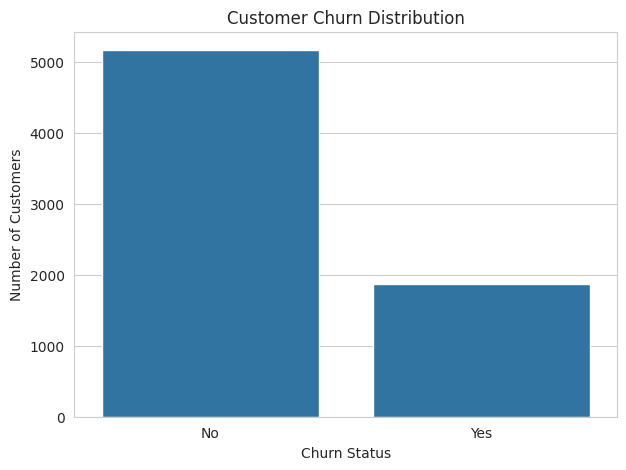

In [10]:
# Analyze customer churn distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [11]:
# Calculate percentage of churned and retained customers

churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


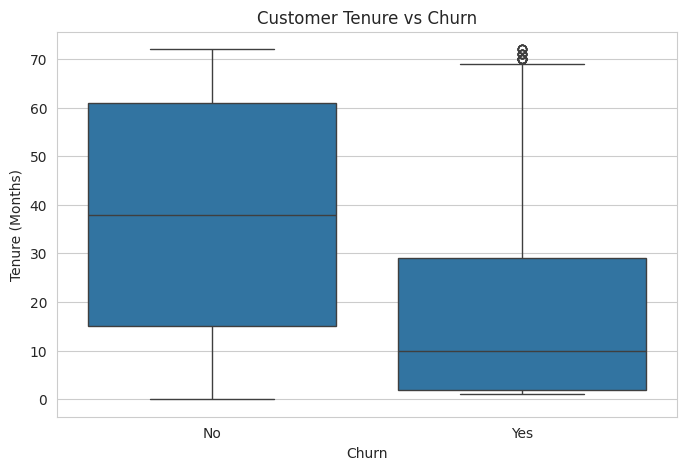

In [12]:
# Compare customer tenure with churn status

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

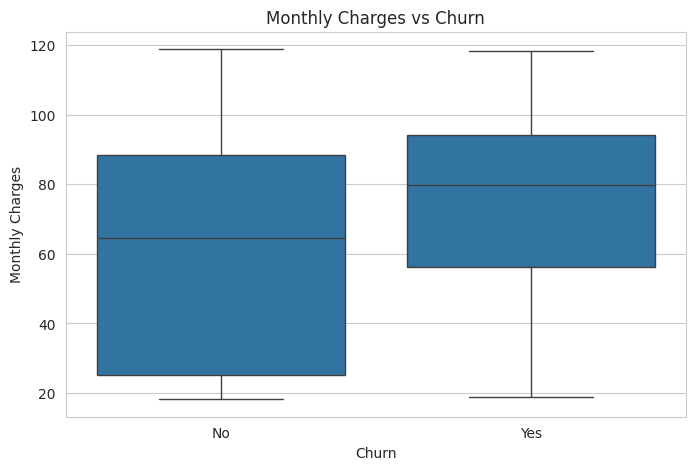

In [13]:
# Analyze monthly charges based on churn status

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

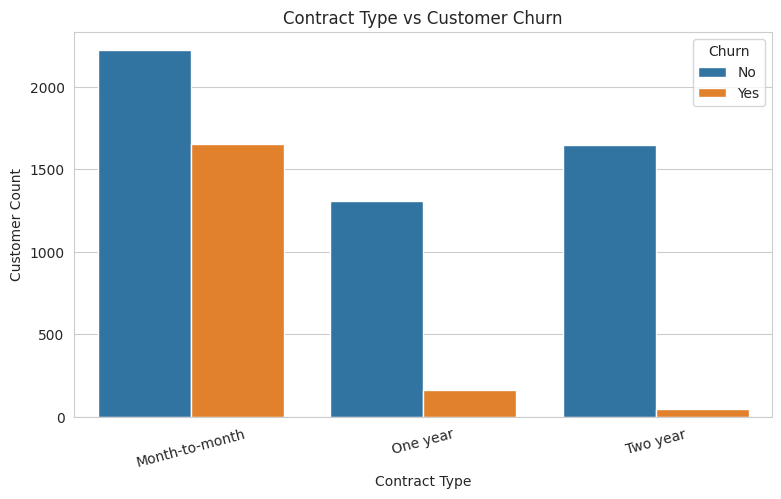

In [14]:
# Analyze churn across different contract types

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Customer Count")

plt.xticks(rotation=15)
plt.show()

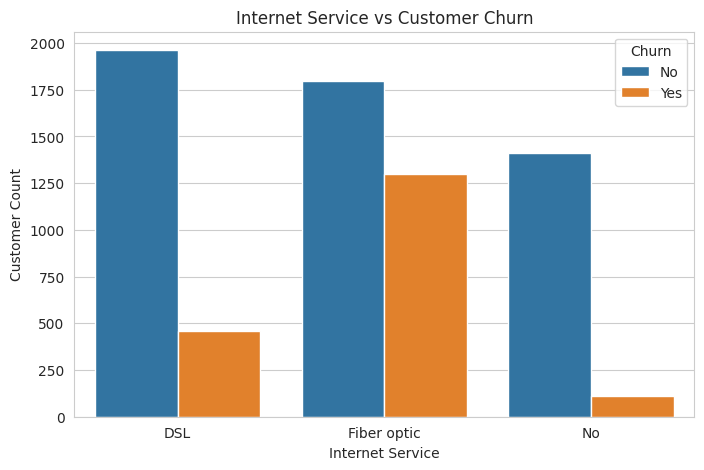

In [15]:
# Analyze churn based on internet service type

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='InternetService', hue='Churn')

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Customer Count")

plt.show()

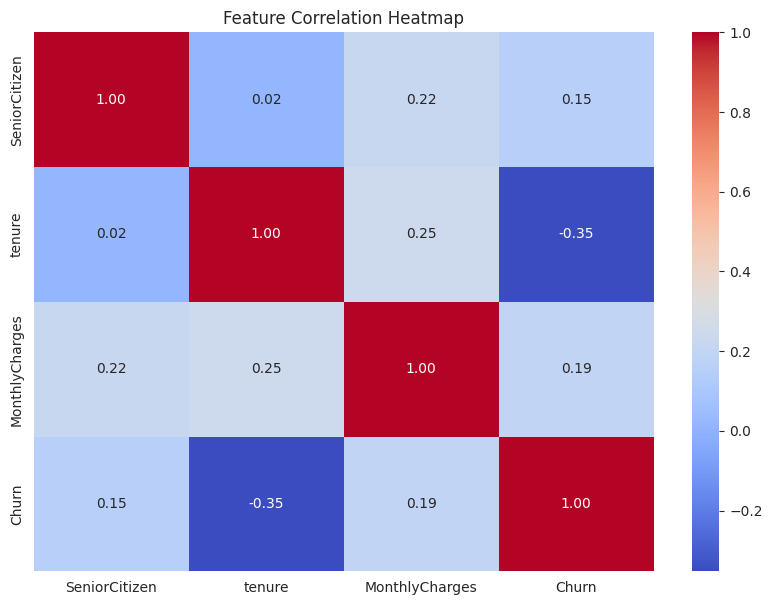

In [16]:
# Convert churn into numeric format for correlation analysis

correlation_df = df.copy()

correlation_df['Churn'] = correlation_df['Churn'].map({
    'Yes': 1,
    'No': 0
})

# Select numerical columns
numeric_df = correlation_df.select_dtypes(include=np.number)

# Plot correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [17]:
# Convert TotalCharges into numeric format

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check missing values after conversion
print("Missing TotalCharges:", df['TotalCharges'].isnull().sum())

# Fill missing charges for customers with zero tenure
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify cleaned column
print(df['TotalCharges'].dtype)

Missing TotalCharges: 11
float64


In [18]:
# Remove duplicate customer records

df = df.drop_duplicates()

# Verify duplicates
print("Remaining Duplicates:", df.duplicated().sum())

Remaining Duplicates: 0


In [19]:
# Verify cleaned dataset

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

df.head()

Dataset Shape: (7043, 21)

Missing Values:
0

Duplicate Rows:
0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
# Remove customer ID because it is not useful for prediction

X = df.drop(columns=['customerID', 'Churn'])

# Store target variable
y = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

# Check feature and target dimensions
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 19)
Target Shape: (7043,)


In [21]:
# Identify numerical and categorical features

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", numeric_features)

print("\nCategorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [22]:
# Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 19)
Testing Data: (1409, 19)


In [23]:
# Import preprocessing tools

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [24]:
# Import classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Machine Learning libraries imported successfully")

Machine Learning libraries imported successfully


In [25]:
# Build Logistic Regression pipeline

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

print("Logistic Regression Pipeline Created")

Logistic Regression Pipeline Created


In [26]:
# Train Logistic Regression model

logistic_model.fit(X_train, y_train)

# Generate predictions
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Training Completed")

Logistic Regression Training Completed


In [27]:
# Build Random Forest classification pipeline

random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest Pipeline Created")

Random Forest Pipeline Created


In [28]:
# Train Random Forest model

random_forest_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = random_forest_model.predict(X_test)

print("Random Forest Training Completed")

Random Forest Training Completed


In [29]:
# Create evaluation function

def evaluate_model(model, X_test, y_test, model_name):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probabilities)
    }

    return results


# Evaluate both models

logistic_results = evaluate_model(
    logistic_model, X_test, y_test, 'Logistic Regression'
)

rf_results = evaluate_model(
    random_forest_model, X_test, y_test, 'Random Forest'
)

# Create comparison table

results_df = pd.DataFrame([
    logistic_results,
    rf_results
])

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
0  Logistic Regression    0.8055     0.6572  0.5588    0.6040   0.8421
1        Random Forest    0.7750     0.5621  0.6898    0.6194   0.8375


In [30]:
# Generate detailed classification report

print("Random Forest Classification Report")

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=['No Churn', 'Churn']
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

    No Churn       0.88      0.81      0.84      1035
       Churn       0.56      0.69      0.62       374

    accuracy                           0.78      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.78      0.78      1409



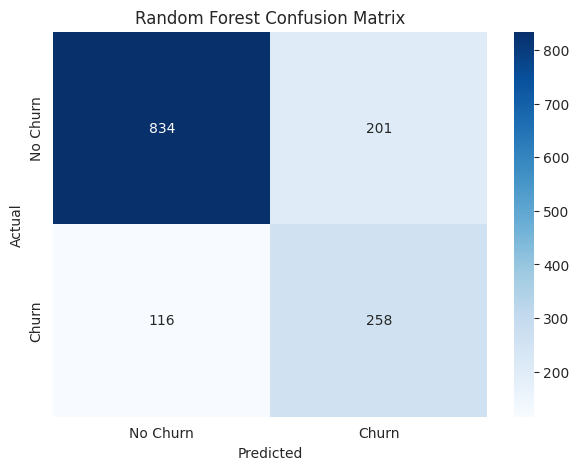

In [31]:
# Generate confusion matrix

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

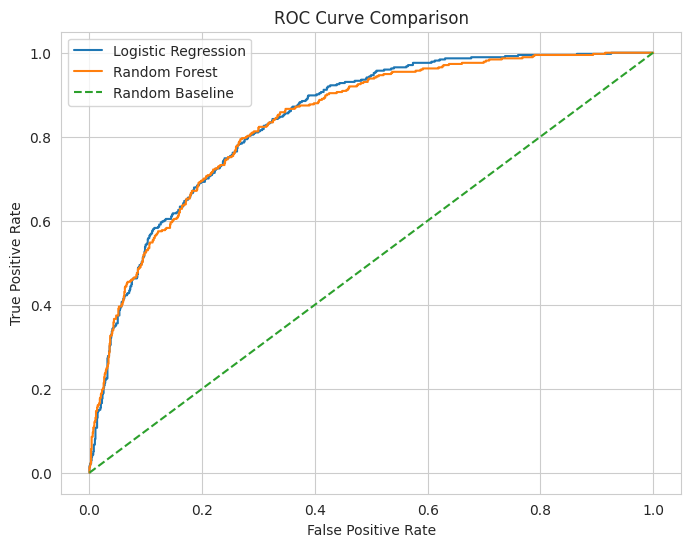

In [32]:
# Plot ROC curve for both models

from sklearn.metrics import roc_curve

logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_test, logistic_probabilities)

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label='Logistic Regression')

plt.plot(fpr_rf, tpr_rf, label='Random Forest')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Baseline')

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.show()

In [33]:
# Extract trained Random Forest model

rf_classifier = random_forest_model.named_steps['classifier']

# Get transformed feature names
feature_names = random_forest_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Create feature importance dataframe
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(15))

                                Feature  Importance
1                           num__tenure    0.127554
3                     num__TotalCharges    0.112557
36         cat__Contract_Month-to-month    0.103235
2                   num__MonthlyCharges    0.086297
18               cat__OnlineSecurity_No    0.054991
38               cat__Contract_Two year    0.053110
27                  cat__TechSupport_No    0.043202
16     cat__InternetService_Fiber optic    0.042636
43  cat__PaymentMethod_Electronic check    0.033695
37               cat__Contract_One year    0.017869
21                 cat__OnlineBackup_No    0.017550
15             cat__InternetService_DSL    0.013996
40            cat__PaperlessBilling_Yes    0.013343
20              cat__OnlineSecurity_Yes    0.012853
39             cat__PaperlessBilling_No    0.012685


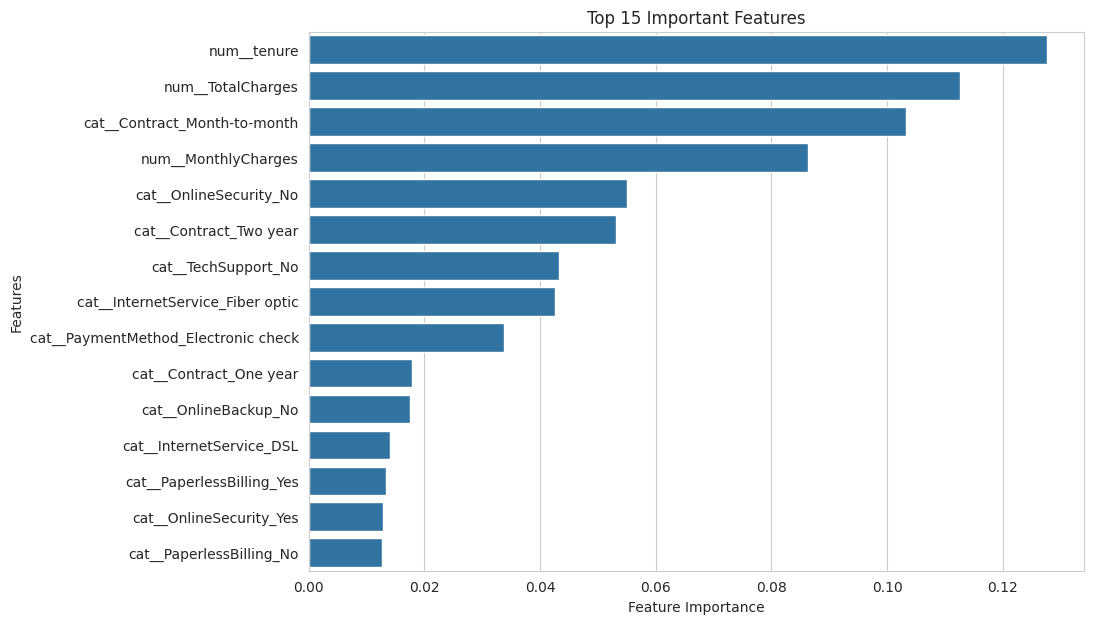

In [34]:
# Plot top 15 important features

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()

In [35]:
# Evaluate Random Forest using cross validation

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

print("Cross Validation Scores:", cv_scores)

print("Mean ROC-AUC:", cv_scores.mean().round(4))

print("Standard Deviation:", cv_scores.std().round(4))

Cross Validation Scores: [0.86175537 0.85481395 0.84205605 0.83630217 0.82389707]
Mean ROC-AUC: 0.8438
Standard Deviation: 0.0134


In [36]:
# Compare models based on F1 score

best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(),
    'Model'
]

print("Best Model:", best_model_name)

# Select the best trained model
if best_model_name == 'Random Forest':
    best_model = random_forest_model
else:
    best_model = logistic_model

print("Best Model Selected Successfully")

Best Model: Random Forest
Best Model Selected Successfully


In [37]:
# Predict churn probability for test customers

final_predictions = best_model.predict(X_test)

final_probabilities = best_model.predict_proba(X_test)[:, 1]

# Create prediction dataframe
prediction_df = pd.DataFrame({
    'Actual_Churn': y_test.values,
    'Predicted_Churn': final_predictions,
    'Churn_Probability': final_probabilities
})

# Convert numeric predictions into labels
prediction_df['Predicted_Status'] = prediction_df[
    'Predicted_Churn'
].map({
    0: 'No Churn',
    1: 'Churn'
})

prediction_df.head(10)

,Actual_Churn,Predicted_Churn,Churn_Probability,Predicted_Status
0,0,0,0.009282,No Churn
1,0,1,0.813693,Churn
2,0,0,0.095591,No Churn
3,0,0,0.390374,No Churn
4,0,0,0.029684,No Churn
5,0,1,0.733601,Churn
6,0,0,0.472524,No Churn
7,0,0,0.148634,No Churn
8,0,0,0.006006,No Churn
9,1,1,0.533806,Churn


In [38]:
# Calculate predicted churn summary

print("Total Customers:", len(prediction_df))

print(
    "Predicted Churn Customers:",
    (prediction_df['Predicted_Churn'] == 1).sum()
)

print(
    "Predicted Retained Customers:",
    (prediction_df['Predicted_Churn'] == 0).sum()
)

print(
    "Average Churn Probability:",
    round(prediction_df['Churn_Probability'].mean() * 100, 2),
    "%"
)

Total Customers: 1409
Predicted Churn Customers: 459
Predicted Retained Customers: 950
Average Churn Probability: 35.07 %


In [39]:
# Import joblib

import joblib

# Save trained model pipeline
joblib.dump(best_model, 'customer_churn_model.pkl')

print("Model Saved Successfully")

Model Saved Successfully


In [40]:
# Export customer prediction results

prediction_df.to_csv(
    'customer_churn_predictions.csv',
    index=False
)

print("Prediction CSV Exported Successfully")

Prediction CSV Exported Successfully


In [41]:
# Download trained model

from google.colab import files

files.download('customer_churn_model.pkl')

# Download prediction results
files.download('customer_churn_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>